<a href="https://colab.research.google.com/github/Amulya-Rao-mj/ML2_lab--Amulya-Rao-M-J--4NI23CI013/blob/main/LAB_9_Bayesian_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
!pip install -q pgmpy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

# Load dataset
dataset = load_breast_cancer(as_frame=True)

df = dataset.frame.copy()

# Convert target values into diagnosis labels
df['Diagnosis'] = df['target'].map({
    0: 'Malignant',
    1: 'Benign'
})

df = df.drop(columns=['target'])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

print("\nDiagnosis distribution:")
print(df['Diagnosis'].value_counts())

Dataset loaded successfully!
Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant



Diagnosis distribution:
Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


Bayesian Network trained successfully!
Network edges: [('Diagnosis', 'mean radius'), ('Diagnosis', 'mean texture'), ('Diagnosis', 'mean perimeter'), ('Diagnosis', 'mean area')]


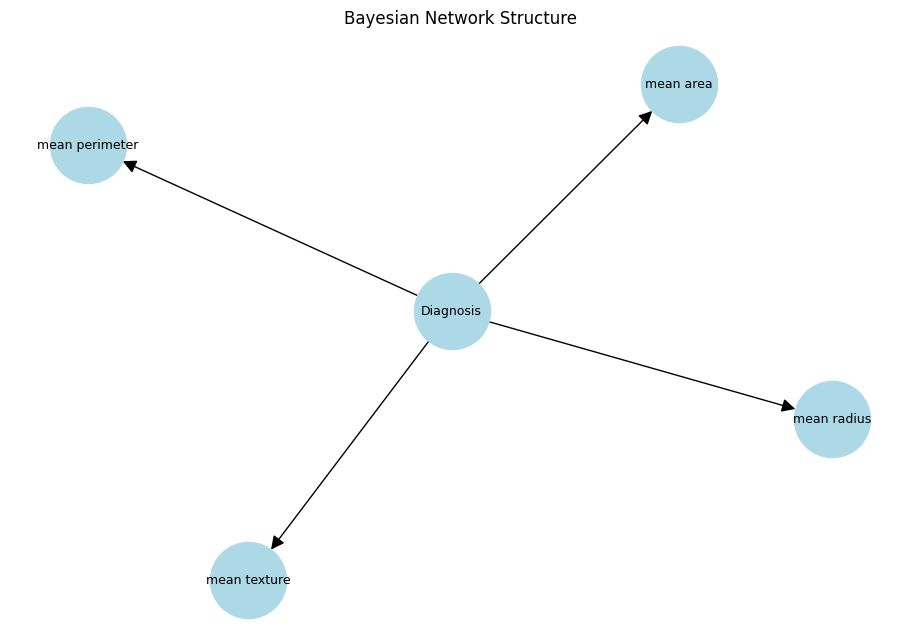

In [15]:
# Select four important features
features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area'
]

X = df[features]
y = df['Diagnosis']

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert numerical values into 3 categories
discretizer = KBinsDiscretizer(
    n_bins=3,
    encode='ordinal',
    strategy='quantile'
)

X_train_d = discretizer.fit_transform(X_train).astype(int)
X_test_d = discretizer.transform(X_test).astype(int)

# Create training dataframe
train_data = pd.DataFrame(
    X_train_d,
    columns=features
)

train_data['Diagnosis'] = y_train.to_numpy()

test_data = pd.DataFrame(
    X_test_d,
    columns=features
)

test_data['Diagnosis'] = y_test.to_numpy()

# Create Bayesian Network structure
edges = [('Diagnosis', feature) for feature in features]

model = DiscreteBayesianNetwork(edges)

# Learn conditional probability distributions by instantiating the MaximumLikelihoodEstimator correctly
estimator = MaximumLikelihoodEstimator(model, train_data)
model.fit(
    train_data,
    estimator=estimator
)

# Create inference engine
inference = VariableElimination(model)

print("Bayesian Network trained successfully!")
print("Network edges:", list(model.edges()))

# Display Bayesian Network
G = nx.DiGraph(model.edges())

plt.figure(figsize=(9, 6))
pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_color='lightblue',
    node_size=3000,
    font_size=9,
    arrows=True,
    arrowsize=20
)

plt.title("Bayesian Network Structure")
plt.show()

Model Accuracy: 85.96 %

Classification Report:
              precision    recall  f1-score   support

      Benign       0.85      0.94      0.89        72
   Malignant       0.88      0.71      0.79        42

    accuracy                           0.86       114
   macro avg       0.87      0.83      0.84       114
weighted avg       0.86      0.86      0.86       114



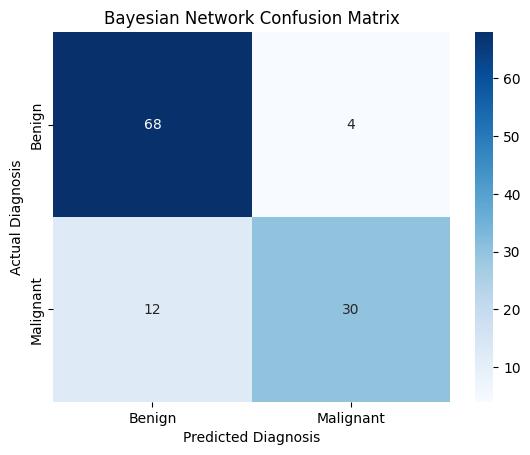


Probability prediction for first test sample:
Actual diagnosis: Benign
Predicted diagnosis: Benign
Probability of Malignant: 0.0 %
Probability of Benign: 100.0 %


In [16]:
# Predict diagnosis using Bayesian inference
predictions = []
malignant_probabilities = []

for _, row in test_data.iterrows():

    evidence = {
        feature: int(row[feature])
        for feature in features
    }

    result = inference.query(
        variables=['Diagnosis'],
        evidence=evidence,
        show_progress=False
    )

    states = result.state_names['Diagnosis']
    probabilities = dict(zip(states, result.values))

    predicted = max(probabilities, key=probabilities.get)

    predictions.append(predicted)
    malignant_probabilities.append(
        probabilities.get('Malignant', 0)
    )

# Calculate accuracy
actual = test_data['Diagnosis'].to_numpy()

accuracy = accuracy_score(actual, predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(actual, predictions))

# Confusion matrix
cm = confusion_matrix(
    actual,
    predictions,
    labels=['Benign', 'Malignant']
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")
plt.title("Bayesian Network Confusion Matrix")
plt.show()

# Display probability for one test sample
print("\nProbability prediction for first test sample:")

print("Actual diagnosis:", actual[0])
print("Predicted diagnosis:", predictions[0])
print(
    "Probability of Malignant:",
    round(malignant_probabilities[0] * 100, 2), "%"
)
print(
    "Probability of Benign:",
    round((1 - malignant_probabilities[0]) * 100, 2), "%"
)
